# Оценка цены автомобиля

Сравниваю Ridge и случайный лес с медианой похожих объявлений. Проверяю, насколько
точно можно оценить запрашиваемую цену по характеристикам машины. Основная метрика — MAE.
Такая оценка может служить продавцу ориентиром при публикации объявления.

Учебный анализ 50 000 объявлений eBay Kleinanzeigen из Германии за март — апрель 2016 года.
Использую [выборку Dataquest](https://www.dataquest.io/blog/cleaning-and-analyzing-used-car-listings-from-ebay-kleinanzeigen/).
В `price` указана цена объявления, а не завершённой сделки. Валюта учебной копии не установлена,
поэтому цены и MAE показываю в единицах этого поля.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
sns.set_theme(style='whitegrid', palette=['#2b6f8e', '#dc8848', '#87959e'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'font.family': 'DejaVu Sans'})
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
pd.set_option('display.max_colwidth', None)

## Проверка данных

In [2]:
raw = pd.read_csv('data/raw/autos.csv', encoding='latin-1')
crawled = pd.to_datetime(raw['dateCrawled'], errors='raise')

display(raw.head(3))
data_audit = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing_n': raw.isna().sum(),
    'missing_pct': raw.isna().mean().mul(100),
    'unique_n': raw.nunique(dropna=False),
})
display(data_audit)
print(f'Объявлений: {len(raw):,}; полей: {raw.shape[1]}')
print(f'Период сбора: {crawled.min():%d.%m.%Y} — {crawled.max():%d.%m.%Y}')
print(f'Полных дубликатов: {raw.duplicated().sum()}')

,dateCrawled,name,seller,offerType,price,abtest,vehicleType,yearOfRegistration,gearbox,powerPS,model,odometer,monthOfRegistration,fuelType,brand,notRepairedDamage,dateCreated,nrOfPictures,postalCode,lastSeen
0,2016-03-26 17:47:46,Peugeot_807_160_NAVTECH_ON_BOARD,privat,Angebot,"$5,000",control,bus,2004,manuell,158,andere,"150,000km",3,lpg,peugeot,nein,2016-03-26 00:00:00,0,79588,2016-04-06 06:45:54
1,2016-04-04 13:38:56,BMW_740i_4_4_Liter_HAMANN_UMBAU_Mega_Optik,privat,Angebot,"$8,500",control,limousine,1997,automatik,286,7er,"150,000km",6,benzin,bmw,nein,2016-04-04 00:00:00,0,71034,2016-04-06 14:45:08
2,2016-03-26 18:57:24,Volkswagen_Golf_1.6_United,privat,Angebot,"$8,990",test,limousine,2009,manuell,102,golf,"70,000km",7,benzin,volkswagen,nein,2016-03-26 00:00:00,0,35394,2016-04-06 20:15:37


,dtype,missing_n,missing_pct,unique_n
dateCrawled,object,0,0.00,48213
name,object,0,0.00,38754
seller,object,0,0.00,2
offerType,object,0,0.00,2
price,object,0,0.00,2357
abtest,object,0,0.00,2
vehicleType,object,5095,10.19,9
yearOfRegistration,int64,0,0.00,97
gearbox,object,2680,5.36,3
powerPS,int64,0,0.00,448


Объявлений: 50,000; полей: 20
Период сбора: 05.03.2016 — 07.04.2016
Полных дубликатов: 0


In [3]:
price_numeric = pd.to_numeric(
    raw['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False),
    errors='coerce',
)
odometer_numeric = pd.to_numeric(
    raw['odometer'].str.replace('km', '', regex=False).str.replace(',', '', regex=False),
    errors='coerce',
)
raw_numeric = pd.DataFrame({
    'price': price_numeric,
    'year': raw['yearOfRegistration'],
    'odometer_km': odometer_numeric,
    'power_ps': raw['powerPS'],
})
display(raw_numeric.describe(percentiles=[.01, .25, .5, .75, .99]).T)
print(f'Нулевых цен: {price_numeric.eq(0).sum():,}')
print(f'Нераспознанных или отрицательных цен: {(price_numeric.isna() | price_numeric.lt(0)).sum()}')
print(f'Доля объявлений в верхней категории пробега: {odometer_numeric.eq(150_000).mean():.1%}')

,count,mean,std,min,1%,25%,50%,75%,99%,max
price,"50,000.00","9,840.04","481,104.38",0.00,0.00,"1,100.00","2,950.00","7,200.00","35,900.00","99,999,999.00"
year,"50,000.00","2,005.07",105.71,"1,000.00","1,978.00","1,999.00","2,003.00","2,008.00","2,018.00","9,999.00"
odometer_km,"50,000.00","125,732.70","40,042.21","5,000.00","5,000.00","125,000.00","150,000.00","150,000.00","150,000.00","150,000.00"
power_ps,"50,000.00",116.36,209.22,0.00,0.00,70.00,105.00,150.00,344.00,"17,700.00"


Нулевых цен: 1,421
Нераспознанных или отрицательных цен: 0
Доля объявлений в верхней категории пробега: 64.8%


В 1 421 объявлении цена равна нулю. В годах регистрации встречаются значения от 1000 до 9999,
а мощность достигает 17 700 PS — эти поля требуют очистки.

У 64,8% объявлений пробег записан как 150 000 км. Это верхняя категория источника,
которая объединяет и машины с большим пробегом. Больше всего пропусков в сведениях
о ремонте: 19,7%; заполню их внутри моделей.

## Проверка смысла цены

По заголовку проверяю, относится ли цена к продаже конкретной машины.
Полного текста объявлений в выборке нет.

In [4]:
reference_offers = raw['name'].str.contains(
    r'Wir_kaufen_Mercedes_sl_r107|Leasing__Leasinguebernahme_530d_Voll',
    case=False, na=False,
)
display(raw.loc[reference_offers, [
    'name', 'price', 'offerType', 'yearOfRegistration', 'powerPS', 'odometer',
]])

,name,price,offerType,yearOfRegistration,powerPS,odometer
8215,Wir_kaufen_Mercedes_sl_r107,"$50,000",Angebot,1960,0,"5,000km"
49650,Leasing__Leasinguebernahme_530d_Voll_580_Brutto__LCI_,$580,Angebot,2014,258,"40,000km"


`Wir_kaufen_Mercedes_sl_r107` — заявка на покупку Mercedes, хотя `offerType`
равен `Angebot`. Здесь 50 000 нельзя трактовать как цену выставленной машины.
В заголовке BMW прямо указана переуступка лизинга (`Leasinguebernahme`);
указаны 2014 год, 258 PS и пробег 40 000 км. Значение 580 может быть платежом,
но его периодичность и полная стоимость в данных отсутствуют.

Исключаю заголовки с `wir kaufen`, `Ankauf` или начальным `Kaufe`, а также явную
передачу лизинга (`Leasingübernahme`, `Leasinguebernahme`, `Leasingsübergabe`
и варианты с пробелом). Прямую продажу с `zu verkaufen` или `Sofortkauf` сохраняю.
Одного упоминания `Leasing` для исключения недостаточно.

In [5]:
titles = raw['name'].str.lower().str.replace(r'[_\W]+', ' ', regex=True).str.strip()
buy_request = titles.str.contains(r'\bwir kaufen\b|\bankauf\b|^kaufe\b', na=False)
lease_transfer = titles.str.contains(
    r'\bleasings?\s*(?:uebernahme|übernahme|uebergabe|übergabe)', na=False,
)
direct_sale = titles.str.contains(r'\bsofortkauf\b|\bzu verkaufen\b', na=False)
non_sale_offer = buy_request | (lease_transfer & ~direct_sale)
print(f'Исключено по смыслу заголовка во всём CSV: {non_sale_offer.sum()}')
display(raw.loc[non_sale_offer, ['name', 'price']].head(6))

retained_leasing = titles.str.contains('leas', na=False) & ~non_sale_offer
retained_leasing &= price_numeric.between(500, 50_000)
display(raw.loc[retained_leasing, ['name', 'price']])

Исключено по смыслу заголовка во всём CSV: 40


,name,price
301,Kaufe_alle_Autos_bietet_an,$0
1733,Leasinguebernahme_BMW_116i_mit_136_PS__Alpinweiss__5_Tuerer,$199
3093,Kaufe_alle_Audi_&_VW_modelle,"$10,000"
3527,Autos_Ankauf_Dortmund,$0
4043,Leasinguebernahme_BMW118i_Automatik_LCI_Facelift,$300
6308,Kaufe_Autos_jeglicher,$0


,name,price
21753,Nur_an_Haendler_zu_verkaufen__oder_Leasinguebernahme!,"$18,798"
42454,Volkswagen_Touareg_3.0_V6_TDI_Blue_Motion_MwSt._da_Leasing,"$44,900"
47223,Bmw_116i_sehr_gepflegtes_Leasing_Auto,"$12,500"


## Подготовка объявлений

Оставляю цены от 500 до 50 000 и год регистрации от 1886 до года сбора объявления.
Ценовой диапазон задаю до обучения, чтобы сравнивать модели в одном сегменте.
Мощность вне 20–600 PS заменяю пропуском и добавляю флаг неизвестного значения.

In [6]:
cars = raw.drop_duplicates().copy()
cars['price'] = price_numeric.loc[cars.index]
cars['odometer_km'] = odometer_numeric.loc[cars.index]
cars['collected_year'] = crawled.loc[cars.index].dt.year

# Похожие объявления оставляю в одной группе, чтобы они не попали одновременно в train и test.
group_columns = [
    'name', 'brand', 'model', 'yearOfRegistration', 'odometer_km', 'powerPS', 'postalCode',
]
group_key = cars[group_columns].copy()
for column in ['name', 'brand', 'model']:
    group_key[column] = group_key[column].fillna('__unknown__').str.strip().str.lower()
    group_key[column] = group_key[column].str.replace(r'\s+', ' ', regex=True)
group_key['postalCode'] = group_key['postalCode'].astype(str).str.zfill(5)
cars['group_id'] = pd.MultiIndex.from_frame(group_key).factorize(sort=False)[0]
group_sizes = cars.groupby('group_id').size()
print(f'Групп с повторными объявлениями до фильтров: {group_sizes.gt(1).sum()}')

Групп с повторными объявлениями до фильтров: 335


In [7]:
price_min, price_max = 500, 50_000
cars = cars.loc[cars['price'].notna() & cars['price'].gt(0)].copy()
positive_price_count = len(cars)
cars = cars.loc[cars['price'].between(price_min, price_max)].copy()
price_scope_removed = positive_price_count - len(cars)
cars = cars.loc[cars['yearOfRegistration'].between(1886, cars['collected_year'])].copy()
cars = cars.loc[cars['odometer_km'].notna() & cars['odometer_km'].ge(0)].copy()

excluded_in_scope = non_sale_offer.loc[cars.index]
print(f'Из числовой области дополнительно исключено по заголовку: {excluded_in_scope.sum()}')
cars = cars.loc[~excluded_in_scope].copy()

power_min, power_max = 20, 600
invalid_power = ~cars['powerPS'].between(power_min, power_max)
cars['power_ps'] = cars['powerPS'].where(~invalid_power)
cars['power_unknown'] = invalid_power.astype(int)
cars['age'] = cars['collected_year'] - cars['yearOfRegistration']
age_labels = ['0–5 лет', '6–10 лет', '11–15 лет', 'Старше 15 лет']
cars['age_group'] = pd.cut(cars['age'], [-1, 5, 10, 15, np.inf], labels=age_labels)
cars['age_group'] = cars['age_group'].astype(object).fillna('Неизвестно')

numeric_features = ['age', 'odometer_km', 'power_ps', 'power_unknown']
categorical_features = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
features = numeric_features + categorical_features

assert cars['price'].notna().all() and cars['price'].gt(0).all(), 'Для APE нужны положительные цены'
display(cars[features].isna().sum().rename('missing_n').to_frame())
print(f'После очистки: {len(cars):,} из {len(raw):,} объявлений ({len(cars) / len(raw):.1%})')
print(f'Вне ценового диапазона: {price_scope_removed:,} из {positive_price_count:,} положительных цен')
print(f'Мощность заменена пропуском в {invalid_power.sum():,} объявлениях')

Из числовой области дополнительно исключено по заголовку: 13


,missing_n
age,0
odometer_km,0
power_ps,3593
power_unknown,0
brand,0
model,1798
vehicleType,1895
gearbox,1591
fuelType,2514
notRepairedDamage,6752


После очистки: 43,126 из 50,000 объявлений (86.3%)
Вне ценового диапазона: 3,668 из 48,579 положительных цен
Мощность заменена пропуском в 3,593 объявлениях


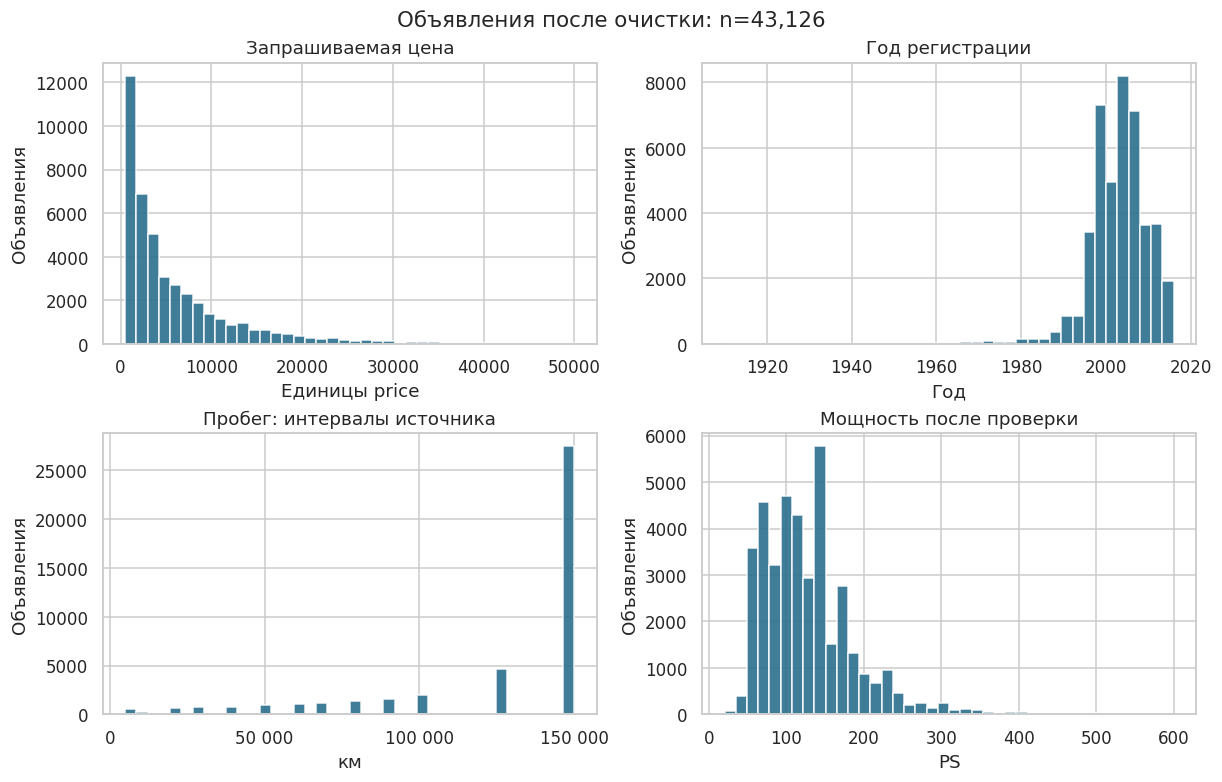

In [8]:
reports_dir = Path('reports')
figures_dir = reports_dir / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
for ax, column, title, xlabel in [
    (axes[0, 0], 'price', 'Запрашиваемая цена', 'Единицы price'),
    (axes[0, 1], 'yearOfRegistration', 'Год регистрации', 'Год'),
    (axes[1, 0], 'odometer_km', 'Пробег: интервалы источника', 'км'),
    (axes[1, 1], 'power_ps', 'Мощность после проверки', 'PS'),
]:
    ax.hist(cars[column].dropna(), bins=40, color='#2b6f8e', alpha=.9)
    ax.set(title=title, xlabel=xlabel, ylabel='Объявления')
axes[1, 0].set_xticks([0, 50_000, 100_000, 150_000], ['0', '50 000', '100 000', '150 000'])
fig.suptitle(f'Объявления после очистки: n={len(cars):,}', fontsize=14)
fig.savefig(figures_dir / 'data_distributions.png', bbox_inches='tight')
plt.show()

## Разбиение выборки

Выделяю 20% групп на test, затем четверть оставшихся групп — на validation.
Объявления с одинаковым составным ключом остаются в одной части; цена в ключ не входит.
Без VIN такой ключ лишь приближённо определяет повторные объявления.

In [9]:
splitter = GroupShuffleSplit(n_splits=1, test_size=.20, random_state=SEED)
trainval_pos, test_pos = next(splitter.split(cars, groups=cars['group_id']))
trainval = cars.iloc[trainval_pos].copy()
test = cars.iloc[test_pos].copy()
splitter_val = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
train_pos, val_pos = next(splitter_val.split(trainval, groups=trainval['group_id']))
train = trainval.iloc[train_pos].copy()
validation = trainval.iloc[val_pos].copy()
parts = {'train': train, 'validation': validation, 'test': test}
group_intersections = sum(
    len(set(parts[left]['group_id']) & set(parts[right]['group_id']))
    for left, right in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]
)
split_summary = pd.DataFrame([
    {'part': name, 'n': len(part), 'groups': part['group_id'].nunique(),
     'row_fraction': len(part) / len(cars)}
    for name, part in parts.items()
])
display(split_summary)
print('Пересечений групп между частями:', group_intersections)
assert group_intersections == 0, 'Похожие объявления пересекаются между частями выборки'
assert sum(len(part) for part in parts.values()) == len(cars), 'При разбиении потерялись строки'

,part,n,groups,row_fraction
0,train,25876,25665,0.60
1,validation,8628,8556,0.20
2,test,8622,8556,0.20


Пересечений групп между частями: 0


## Медианные прогнозы и метрики

Сравниваю общую медиану с медианой аналогов по марке, модели и возрастной группе.
Для аналогов нужны хотя бы 30 объявлений; иначе последовательно беру медиану
по марке и модели, по марке, затем по всей обучающей выборке.

Основная метрика — MAE. Дополнительно считаю медианную абсолютную процентную ошибку
и долю прогнозов с ошибкой не больше 20%. Порог 20% использую как ориентир точности.

In [10]:
min_analogs = 30
analog_levels = [['brand', 'model', 'age_group'], ['brand', 'model'], ['brand']]


def fit_analogs(frame):
    tables = []
    for keys in analog_levels:
        summary = frame.groupby(keys, dropna=False, observed=True)['price'].agg(['median', 'size'])
        tables.append((keys, summary.loc[summary['size'].ge(min_analogs), 'median']))
    return {'global_median': float(frame['price'].median()), 'tables': tables}


def predict_analogs(state, frame):
    predictions = np.full(len(frame), np.nan)
    for keys, table in state['tables']:
        index = pd.MultiIndex.from_frame(frame[keys]) if len(keys) > 1 else pd.Index(frame[keys[0]])
        values = table.reindex(index).to_numpy(dtype=float)
        use = np.isnan(predictions) & ~np.isnan(values)
        predictions[use] = values[use]
    predictions[np.isnan(predictions)] = state['global_median']
    return predictions


def evaluate(actual, predictions):
    actual = np.asarray(actual, dtype=float)
    predictions = np.asarray(predictions, dtype=float)
    ape = np.abs(predictions - actual) / actual
    return {
        'mae': float(mean_absolute_error(actual, predictions)),
        'median_ape_pct': float(100 * np.median(ape)),
        'within_20_pct': float(100 * np.mean(ape <= .20)),
    }

## Ridge и случайный лес

Для числовых признаков заполняю пропуски медианой, для категорий — значением `unknown`.
Ridge также требует масштабирования числовых признаков. Подготовка находится внутри Pipeline
и обучается только на обучающей части выборки.

Обе модели предсказывают `log1p(price)`: это уменьшает влияние дорогих объявлений
при обучении. После обратного преобразования оцениваю прогнозы в исходных единицах цены;
отрицательные значения ограничиваю нулём.

In [11]:
numeric_linear = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
numeric_forest = SimpleImputer(strategy='median')
categorical = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=True)),
])
linear_preprocessor = ColumnTransformer([
    ('numeric', numeric_linear, numeric_features),
    ('categorical', categorical, categorical_features),
])
forest_preprocessor = ColumnTransformer([
    ('numeric', numeric_forest, numeric_features),
    ('categorical', categorical, categorical_features),
])
ridge = TransformedTargetRegressor(
    regressor=Pipeline([
        ('prepare', linear_preprocessor),
        ('model', Ridge(solver='lsqr', tol=1e-5)),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)
forest = TransformedTargetRegressor(
    regressor=Pipeline([
        ('prepare', forest_preprocessor),
        ('model', RandomForestRegressor(n_estimators=160, n_jobs=2, random_state=SEED)),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
)

## Сравнение на validation

Сравниваю две настройки Ridge и две настройки леса по MAE. В каждой семье оставляю
настройку с минимальной MAE, затем сравниваю её с двумя медианными прогнозами.

In [12]:
candidates = [
    ('Ridge α=10', 'Ridge', ridge, {'regressor__model__alpha': 10.0}),
    ('Ridge α=100', 'Ridge', ridge, {'regressor__model__alpha': 100.0}),
    ('Лес depth=16 leaf=5', 'RandomForest', forest,
     {'regressor__model__max_depth': 16, 'regressor__model__min_samples_leaf': 5}),
    ('Лес depth=22 leaf=3', 'RandomForest', forest,
     {'regressor__model__max_depth': 22, 'regressor__model__min_samples_leaf': 3}),
]

median_predictions = np.full(len(validation), train['price'].median())
analog_state = fit_analogs(train)
analog_predictions = predict_analogs(analog_state, validation)
validation_rows = [
    {'candidate': 'Общая медиана', 'family': 'Dummy',
     **evaluate(validation['price'], median_predictions)},
    {'candidate': 'Медиана аналогов', 'family': 'Analogs',
     **evaluate(validation['price'], analog_predictions)},
]
fitted_candidates = {}
for name, family, template, parameters in candidates:
    model = clone(template).set_params(**parameters)
    model.fit(train[features], train['price'])
    predictions = np.maximum(0, model.predict(validation[features]))
    fitted_candidates[name] = model
    validation_rows.append({
        'candidate': name, 'family': family, **evaluate(validation['price'], predictions),
    })

validation_results = pd.DataFrame(validation_rows).set_index('candidate')
display(validation_results.sort_values('mae'))

,family,mae,median_ape_pct,within_20_pct
candidate,,,,
Лес depth=22 leaf=3,RandomForest,"1,435.47",21.03,48.20
Лес depth=16 leaf=5,RandomForest,"1,485.82",21.68,46.49
Ridge α=10,Ridge,"2,174.89",31.05,33.25
Ridge α=100,Ridge,"2,186.29",31.57,32.20
Медиана аналогов,Analogs,"2,710.55",35.71,29.13
Общая медиана,Dummy,"4,377.26",67.89,12.89


In [13]:
family_choice = {}
for family in ['Ridge', 'RandomForest']:
    family_results = validation_results.loc[validation_results['family'].eq(family)]
    family_choice[family] = family_results['mae'].idxmin()

finalists = ['Общая медиана', 'Медиана аналогов', family_choice['Ridge'], family_choice['RandomForest']]
selected_name = validation_results.loc[finalists, 'mae'].idxmin()
print(f'Минимальная MAE на validation: {selected_name}')

Минимальная MAE на validation: Лес depth=22 leaf=3


На validation минимальная MAE у леса с глубиной 22 и минимумом 3 объявления в листе:
1 435,5. У медианы аналогов она равна 2 710,6.

## Важность признаков

Перемешиваю каждый исходный признак и измеряю прирост MAE на 2 000 объявлениях validation,
повторяя расчёт три раза. Модель обучена на train. Так оцениваю, на какие признаки
опирается прогноз; причинную связь этот расчёт не устанавливает.

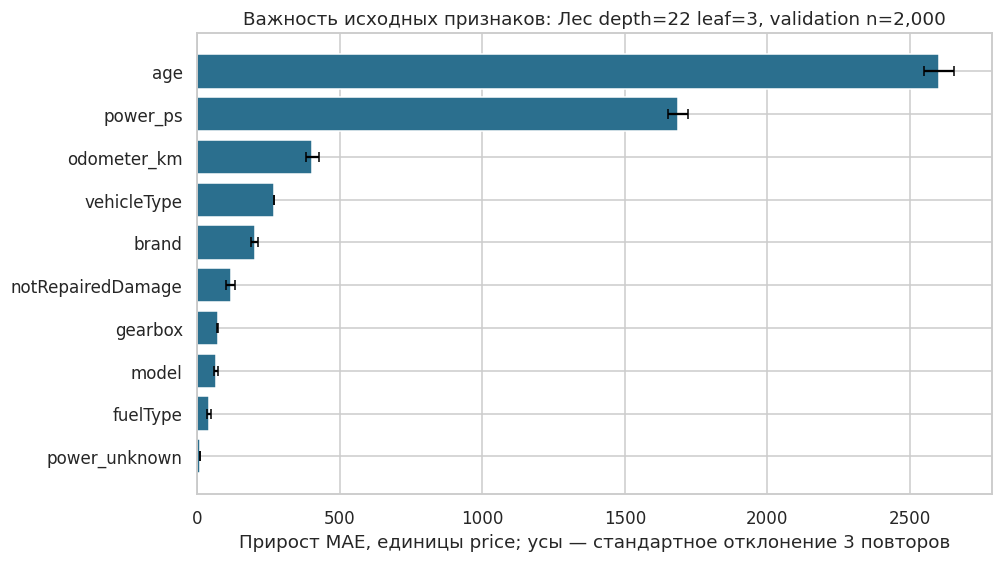

,feature,mae_increase,std
0,age,"2,601.19",53.39
2,power_ps,"1,686.82",34.34
1,odometer_km,403.85,22.71
6,vehicleType,268.81,1.37
4,brand,201.12,13.63
9,notRepairedDamage,117.08,14.54
7,gearbox,71.50,1.72
5,model,66.39,5.96
8,fuelType,40.28,7.12
3,power_unknown,9.80,1.26


In [14]:
importance_sample = validation.sample(n=min(2_000, len(validation)), random_state=SEED)
importance_result = permutation_importance(
    fitted_candidates[selected_name], importance_sample[features], importance_sample['price'],
    scoring='neg_mean_absolute_error', n_repeats=3, random_state=SEED, n_jobs=1,
)
importance_table = pd.DataFrame({
    'feature': features, 'mae_increase': importance_result.importances_mean,
    'std': importance_result.importances_std,
}).sort_values('mae_increase')
fig, ax = plt.subplots(figsize=(9, 5), layout='constrained')
ax.barh(importance_table['feature'], importance_table['mae_increase'],
        xerr=importance_table['std'], color='#2b6f8e', capsize=3)
ax.axvline(0, color='#87959e', linewidth=1)
ax.set(xlabel='Прирост MAE, единицы price; усы — стандартное отклонение 3 повторов',
       title=f'Важность исходных признаков: {selected_name}, validation n={len(importance_sample):,}')
fig.savefig(figures_dir / 'feature_importance.png', bbox_inches='tight')
plt.show()
display(importance_table.sort_values('mae_increase', ascending=False))

Перемешивание возраста увеличило MAE на 2 601,2, мощности — на
1 686,8, пробега — на 403,9. На этой выборке качество прогноза сильнее всего
зависит от возраста и мощности.

## Качество на test

Обучаю выбранные Ridge и лес на train + validation, на тех же объявлениях пересчитываю
обе медианы. Сравниваю четыре метода на отложенном test.

In [15]:
test_predictions = {
    'Общая медиана': np.full(len(test), trainval['price'].median()),
}
final_analogs = fit_analogs(trainval)
test_predictions['Медиана аналогов'] = predict_analogs(final_analogs, test)
for name in [family_choice['Ridge'], family_choice['RandomForest']]:
    model = clone(fitted_candidates[name])
    model.fit(trainval[features], trainval['price'])
    test_predictions[name] = np.maximum(0, model.predict(test[features]))

test_metrics = {
    name: evaluate(test['price'], test_predictions[name])
    for name in finalists
}
comparison = pd.DataFrame(test_metrics).T.add_prefix('test_')
comparison.index.name = 'model'
comparison = comparison.reset_index()
display(comparison[['model', 'test_mae', 'test_median_ape_pct', 'test_within_20_pct']])

ml_metric = test_metrics[selected_name]
analog_metric = test_metrics['Медиана аналогов']
gain = {
    'mae_reduction': analog_metric['mae'] - ml_metric['mae'],
    'mae_reduction_pct': 100 * (1 - ml_metric['mae'] / analog_metric['mae']),
    'within_20_gain_pp': ml_metric['within_20_pct'] - analog_metric['within_20_pct'],
}
print(f'Снижение MAE относительно аналогов: {gain["mae_reduction"]:,.1f} ({gain["mae_reduction_pct"]:.1f}%)')
print(f'Прирост доли прогнозов с ошибкой до 20%: {gain["within_20_gain_pp"]:.1f} п.п.')

,model,test_mae,test_median_ape_pct,test_within_20_pct
0,Общая медиана,"4,422.42",69.14,12.25
1,Медиана аналогов,"2,584.38",34.99,30.42
2,Ridge α=10,"2,155.86",30.42,33.32
3,Лес depth=22 leaf=3,"1,403.52",20.67,48.70


Снижение MAE относительно аналогов: 1,180.9 (45.7%)
Прирост доли прогнозов с ошибкой до 20%: 18.3 п.п.


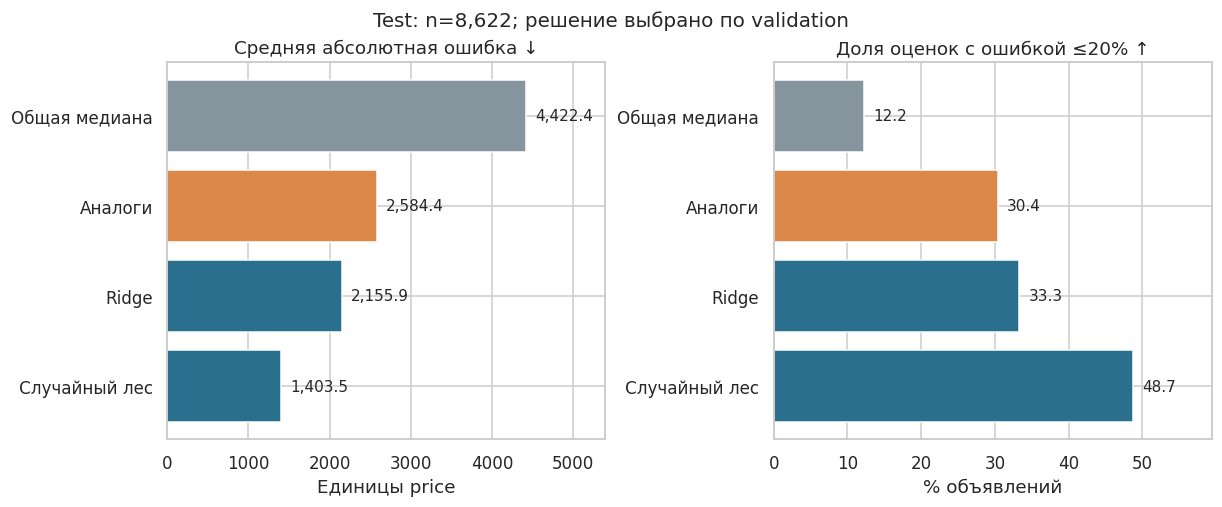

In [16]:
labels = ['Общая медиана', 'Аналоги', 'Ridge', 'Случайный лес']
colors = ['#87959e', '#dc8848', '#2b6f8e', '#2b6f8e']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout='constrained')
for ax, column, title, unit in [
    (axes[0], 'test_mae', 'Средняя абсолютная ошибка ↓', 'Единицы price'),
    (axes[1], 'test_within_20_pct', 'Доля оценок с ошибкой ≤20% ↑', '% объявлений'),
]:
    values = comparison[column].to_numpy()
    ax.barh(labels, values, color=colors)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=unit, xlim=(0, values.max() * 1.22))
    for i, value in enumerate(values):
        ax.text(value + values.max() * .025, i, f'{value:,.1f}', va='center', fontsize=10)
fig.suptitle(f'Test: n={len(test):,}; решение выбрано по validation', fontsize=13)
fig.savefig(figures_dir / 'model_comparison.png', bbox_inches='tight')
plt.show()

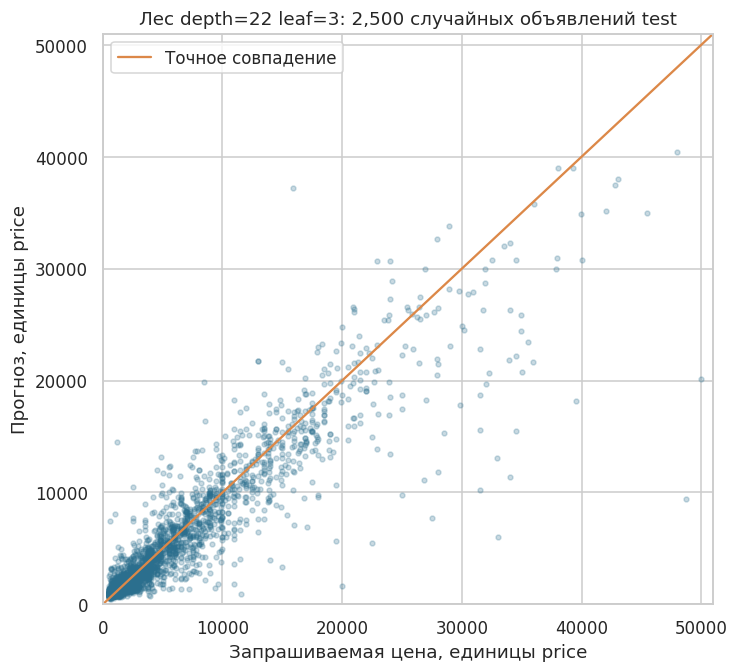

In [17]:
plot_positions = np.random.default_rng(SEED).choice(len(test), min(2_500, len(test)), replace=False)
fig, ax = plt.subplots(figsize=(6.6, 6), layout='constrained')
ax.scatter(test['price'].to_numpy()[plot_positions], test_predictions[selected_name][plot_positions],
           s=10, alpha=.25, color='#2b6f8e', rasterized=True)
limit = max(price_max, float(np.max(test_predictions[selected_name][plot_positions]))) * 1.02
ax.plot([0, limit], [0, limit], color='#dc8848', linewidth=1.5, label='Точное совпадение')
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel='Запрашиваемая цена, единицы price',
       ylabel='Прогноз, единицы price', title=f'{selected_name}: {len(plot_positions):,} случайных объявлений test')
ax.legend()
fig.savefig(figures_dir / 'actual_vs_predicted.png', bbox_inches='tight')
plt.show()

На test лес получил MAE 1 403,5 против 2 584,4 у медианы аналогов — на 45,7% меньше.
Доля прогнозов с ошибкой не больше 20% выросла с 30,4% до 48,7%, на 18,3 п.п.

## Ошибки по сегментам

Сравниваю марки, возрастные группы и диапазоны фактической цены.
Ценовые группы использую только для разбора ошибок. Показываю сегменты
хотя бы со 100 объявлениями.

In [18]:
min_segment = 100
test_detail = test[['name', 'brand', 'age_group', 'price']].copy()
test_detail.index.name = 'source_row'
test_detail['price_band'] = pd.cut(
    test_detail['price'], [499, 1_999, 4_999, 9_999, 19_999, 50_000],
    labels=['500–1 999', '2 000–4 999', '5 000–9 999', '10 000–19 999', '20 000–50 000'],
)
test_detail['pred_ml'] = test_predictions[selected_name]
test_detail['pred_analogs'] = test_predictions['Медиана аналогов']
segment_rows = []
for dimension in ['brand', 'age_group', 'price_band']:
    for segment, frame in test_detail.groupby(dimension, observed=True, sort=False):
        ml = evaluate(frame['price'], frame['pred_ml'])
        analog = evaluate(frame['price'], frame['pred_analogs'])
        segment_rows.append({
            'dimension': dimension, 'segment': str(segment), 'n': len(frame),
            **{f'ml_{key}': value for key, value in ml.items()},
            **{f'analogs_{key}': value for key, value in analog.items()},
            'mae_reduction_pct': 100 * (1 - ml['mae'] / analog['mae']),
            'eligible_n': len(frame) >= min_segment,
        })
segment_errors = pd.DataFrame(segment_rows)
large_segments = segment_errors.loc[segment_errors['eligible_n']]
segment_columns = ['dimension', 'segment', 'n', 'ml_mae', 'analogs_mae', 'ml_within_20_pct', 'analogs_within_20_pct']
display(large_segments[segment_columns].sort_values(['dimension', 'n'], ascending=[True, False]).reset_index(drop=True))

,dimension,segment,n,ml_mae,analogs_mae,ml_within_20_pct,analogs_within_20_pct
0,age_group,Старше 15 лет,2779,996.72,"1,378.13",33.54,26.34
1,age_group,11–15 лет,2523,"1,042.58","1,555.81",46.37,30.44
2,age_group,6–10 лет,2171,"1,692.69","3,056.49",61.63,36.16
3,age_group,0–5 лет,1149,"2,633.58","6,868.36",66.06,29.42
4,brand,volkswagen,1856,"1,295.37","2,426.06",49.14,32.22
5,brand,bmw,997,"1,753.66","3,173.61",50.25,29.49
6,brand,opel,886,786.99,"1,257.74",48.98,34.09
7,brand,mercedes_benz,874,"1,963.97","3,586.13",46.91,31.12
8,brand,audi,779,"1,779.23","3,106.53",55.33,32.86
9,brand,ford,572,939.58,"1,729.93",45.98,32.52


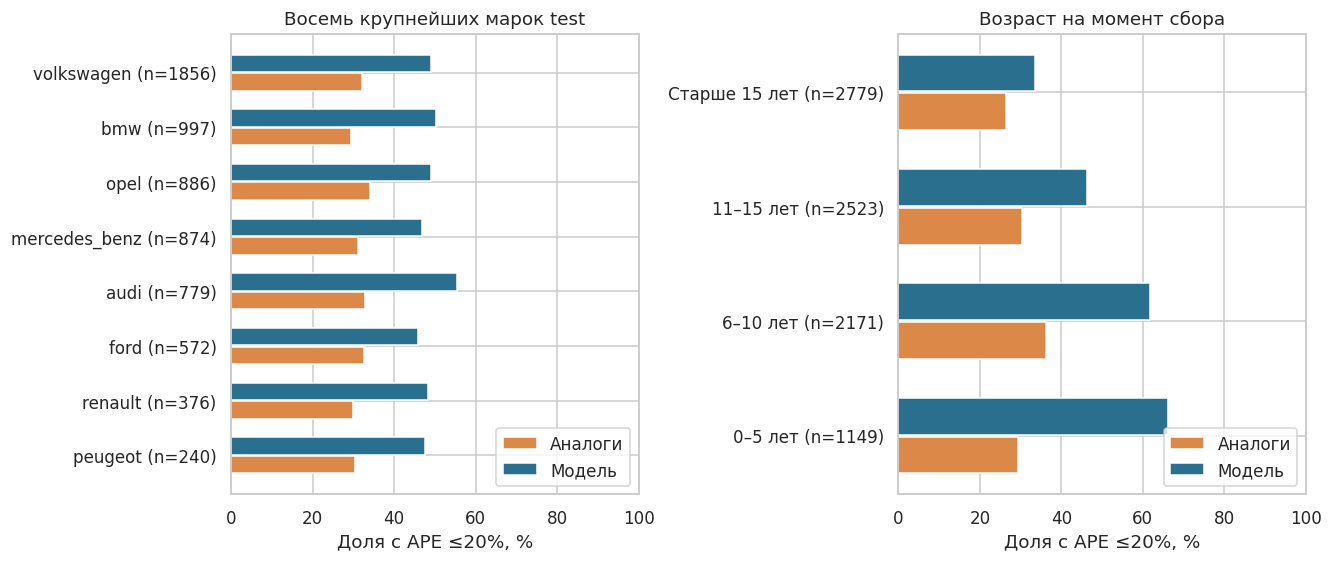

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, dimension, title in [
    (axes[0], 'brand', 'Восемь крупнейших марок test'),
    (axes[1], 'age_group', 'Возраст на момент сбора'),
]:
    subset = large_segments.loc[large_segments['dimension'].eq(dimension)].copy()
    if dimension == 'brand':
        subset = subset.nlargest(8, 'n').sort_values('n')
    else:
        subset = subset.set_index('segment').reindex(age_labels).dropna().reset_index()
    y = np.arange(len(subset))
    ax.barh(y - .17, subset['analogs_within_20_pct'], height=.32, color='#dc8848', label='Аналоги')
    ax.barh(y + .17, subset['ml_within_20_pct'], height=.32, color='#2b6f8e', label='Модель')
    ax.set_yticks(y, [f'{s} (n={n})' for s, n in zip(subset['segment'], subset['n'])])
    ax.set(xlim=(0, 100), xlabel='Доля с APE ≤20%, %', title=title)
    ax.legend(loc='lower right')
fig.savefig(figures_dir / 'segment_errors.png', bbox_inches='tight')
plt.show()

Среди возрастных групп доля прогнозов с ошибкой до 20% выше всего у машин 0–5 лет:
66,1% на 1 149 объявлениях. У машин старше 15 лет она равна 33,5% на 2 779 объявлениях.
В диапазоне цены 500–1 999 MAE составляет 507,0, а в пределы 20% попадают 35,7%
прогнозов. Одна и та же абсолютная ошибка сильнее влияет на относительную ошибку дешёвых машин.

In [20]:
largest_errors = test_detail.assign(
    absolute_error=(test_detail['price'] - test_detail['pred_ml']).abs(),
).nlargest(5, 'absolute_error')
display(largest_errors[[
    'name', 'price', 'pred_ml', 'pred_analogs', 'absolute_error',
]])
display(test.loc[largest_errors.index[:3], [
    'brand', 'model', 'yearOfRegistration', 'powerPS', 'odometer', 'gearbox', 'fuelType',
]])

,name,price,pred_ml,pred_analogs,absolute_error
source_row,,,,,
33189,ALPINA_B10_Bi_Turbo_BiTurbo,48700,"9,409.36","5,727.50","39,290.64"
34562,Toyota_Land_Cruiser,49500,"15,826.72","3,225.00","33,673.28"
46123,Porsche_911S_Modell77_zitronengelb,47000,"14,225.94","33,800.00","32,774.06"
21106,Zu_verkaufen___LAND_ROVER_DEFENDER_110_TD,39900,"7,565.56","11,995.00","32,334.44"
46531,Audi_A6_Avant_Quattro,49999,"20,122.98","24,890.00","29,876.02"


,brand,model,yearOfRegistration,powerPS,odometer,gearbox,fuelType
source_row,,,,,,,
33189,sonstige_autos,NaN,1993,360,"150,000km",NaN,NaN
34562,toyota,andere,2012,0,"40,000km",manuell,diesel
46123,porsche,911,1977,165,"150,000km",manuell,benzin


Все пять крупнейших ошибок — недооценки дорогих объявлений.

- `ALPINA_B10_Bi_Turbo_BiTurbo`: цена 48 700, прогноз 9 409,4.
  Марка записана как `sonstige_autos`, модель, коробка и топливо не указаны.
  Подробное обозначение машины осталось только в заголовке, который не входит в признаки.
- `Toyota_Land_Cruiser`: цена 49 500, прогноз 15 826,7.
  В `model` стоит общая категория `andere`, а `powerPS=0` заменён пропуском.
  Вклад этих полей в конкретную ошибку отдельно не измерялся.
- `Porsche_911S_Modell77_zitronengelb`: цена 47 000, прогноз 14 225,9.
  Указаны модель 911, 1977 год и мощность 165 PS. Эти поля заполнены;
  причину расхождения цены и прогноза по доступным сведениям установить нельзя.

## Сохранение результатов

In [21]:
segment_errors.to_csv(reports_dir / 'segment_errors.csv', index=False)

## Выводы

Случайный лес точнее медианы аналогов: MAE на test равна 1 403,5 против 2 584,4,
ниже на 45,7%. В выбранный ориентир ошибки до 20% укладываются 48,7% прогнозов.
У машин старше 15 лет эта доля равна 33,5%, у машин 0–5 лет — 66,1%.

Модель можно рассматривать как основу ценовой подсказки продавцу. Для оценки её качества
на текущем рынке нужны свежие объявления: расчёт выполнен на данных 2016 года.